<a href="https://colab.research.google.com/github/deira-v/MachineLearningwPython/blob/main/CampusDataProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Campus Dataset Project**
Deira valci, 2026

## **Data Preparation**
This selection loads the campus dataset and prepares it for analysis

In [81]:
# @title
import pandas as pd
import matplotlib.pyplot as plt

In [82]:
# @title
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Load and print the Dataframe**
Read the encoded data
Inspect the dataset structure and remove the empty cells

In [83]:
# @title
df = pd.read_csv('/content/drive/MyDrive/MachineLearningwPython/CampusWalkDataset_Deira.csv', skiprows=4)

print(df.info())
print(f"\n Dataset loaded successfully! Total rows: {df.shape[0]}, Columns: {df.shape[1]}")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   131 non-null    object 
 2   location                               131 non-null    object 
 3   weather                                131 non-null    object 
 4   temperature_c                          131 non-null    object 
 5   sound level                            131 non-null    object 
 6   foot_traffic                           131 non-null    object 
 7   primary_sound_type_urban               131 non-null    object 
 8   other_sound_type_urban                 128 non-null    object 
 9   primary_sound_type_nature              131 non-null    object 
 10  other_sound_type_nature                129 non-null    object 
 11  insect

## **Select data**


### **Sound Level data encoding**

In [84]:
# @title
# Search for 'sound level' in the columns
if 'sound level' in df.columns:
  print(df['sound level'].value_counts(dropna=False))
else:
  print("sound level not found")

sound level
NaN         863
Moderate     58
Quiet        57
Loud         16
Name: count, dtype: int64


In [85]:
# @title
# Define the mapping
sound_mapping = {
    'Quiet': 0,
    'Moderate': 1,
    'Loud': 2
}

# create a new numerical column for the encoded values
df['sound_level_encoded'] = df['sound level'].map(sound_mapping)

# Verify mapping and check data types
print("-- Mapping verification --")
print(df[['sound level', 'sound_level_encoded']]
      .drop_duplicates()
      .reset_index(drop=True)
      )


-- Mapping verification --
  sound level  sound_level_encoded
0       Quiet                  0.0
1    Moderate                  1.0
2        Loud                  2.0
3         NaN                  NaN


### **Distribution plot of the sound level data**

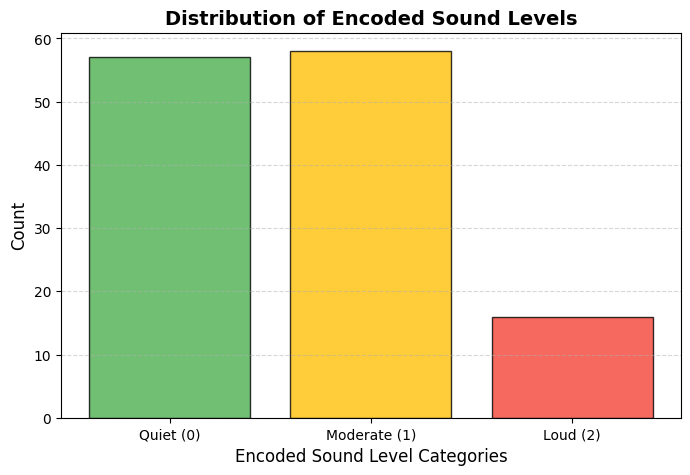

In [86]:
# @title
# Group and count the non-null encoded sound levels
sound_counts = df['sound_level_encoded'].dropna().value_counts().sort_index()

# Map indices back to their labels for the plot x-axis
labels = ['Quiet (0)', 'Moderate (1)', 'Loud (2)']

# Create the bar plot
plt.figure(figsize=(8, 5))
plt.bar(labels, sound_counts.values, color=['#4CAF50', '#FFC107', '#F44336'], edgecolor='black', alpha=0.8)

# Customizing labels and titles
plt.title('Distribution of Encoded Sound Levels', fontsize=14, fontweight='bold')
plt.xlabel('Encoded Sound Level Categories', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Display the plot
plt.show()

### **Weather data encoding**

In [87]:
# @title
# Search for 'weather' in the columns
if 'weather' in df.columns:
  print(df['weather'].value_counts(dropna=False))
else:
  print("weather not found")

weather
NaN              863
Sunny             79
Partly cloudy     36
Cloudy             7
sunny              5
Windy              4
Name: count, dtype: int64


### **Comparing Cluster Distribution Across Weather Conditions**
We will analyze the mapping between our K-Means clusters and the original cleaned weather categories to see if the clustering algorithm has successfully separated the weather profiles.

In [88]:
# @title
# 1. Standardize text to lowercase to fix spelling/case mismatches
df['weather_clean'] = df['weather'].str.strip().str.lower()

# 2. Perform hot encoding on the cleaned weather column
weather_encoded = pd.get_dummies(
    df['weather_clean'],
    prefix='weather',
    dtype=int
)

# 3. Concatenate the new dummy columns back to df
df = pd.concat([df, weather_encoded], axis=1)

print('Cleaned Weather Value Counts:')
print(df['weather_clean'].value_counts(dropna=False))

print("\n--- Encoded Weather Columns Preview ---")
display(df.filter(like='weather_').head())

Cleaned Weather Value Counts:
weather_clean
NaN              863
sunny             84
partly cloudy     36
cloudy             7
windy              4
Name: count, dtype: int64

--- Encoded Weather Columns Preview ---


,weather_clean,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy
0,partly cloudy,0,1,0,0
1,sunny,0,0,1,0
2,partly cloudy,0,1,0,0
3,partly cloudy,0,1,0,0
4,sunny,0,0,1,0


Cluster vs Weather Condition Counts:


weather_clean,Cloudy,Partly cloudy,Sunny,Windy
cluster,,,,
0,0,36,0,0
1,0,0,84,0
2,7,0,0,0
3,0,0,0,4


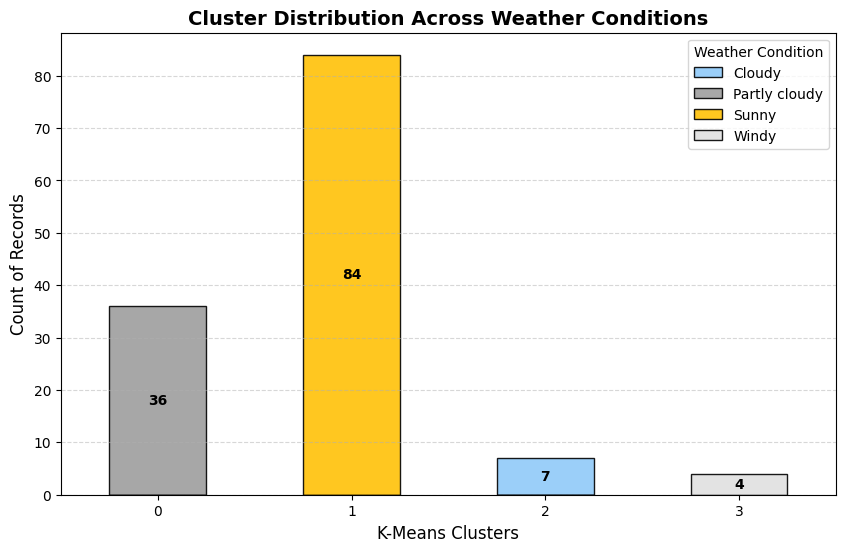

In [89]:
import seaborn as sns

# Group the data to see the counts of each weather condition within each cluster
cluster_weather_dist = weather_df.groupby(['cluster', 'weather_clean']).size().unstack(fill_value=0)

# Display the contingency table
print("Cluster vs Weather Condition Counts:")
display(cluster_weather_dist)

# Create a stacked bar chart
ax = cluster_weather_dist.plot(kind='bar', stacked=True, figsize=(10, 6), color=['#90CAF9', '#9E9E9E', '#FFC107', '#E0E0E0'], edgecolor='black', alpha=0.9)

# Customizing labels and titles
plt.title('Cluster Distribution Across Weather Conditions', fontsize=14, fontweight='bold')
plt.xlabel('K-Means Clusters', fontsize=12)
plt.ylabel('Count of Records', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Weather Condition')

# Add counts on top of the bars
for rect in ax.patches:
    height = rect.get_height()
    width = rect.get_width()
    x = rect.get_x()
    y = rect.get_y()
    if height > 0:
        ax.text(x + width/2., y + height/2., f'{int(height)}', ha='center', va='center', fontsize=10, fontweight='bold', color='black')

plt.show()

### **Encoding and Plotting Wellbeing Rating**
Let's first inspect the values inside the `wellbeing_rating` column, map them to numeric scores, and visualize their distribution.

In [90]:
# @title
# Inspect the unique categories in wellbeing_rating
if 'wellbeing_rating' in df.columns:
    print("Unique wellbeing ratings:")
    print(df['wellbeing_rating'].value_counts(dropna=False))
else:
    print("wellbeing_rating column not found")

Unique wellbeing ratings:
wellbeing_rating
NaN                        863
Positive wellbeing          67
Neutral                     37
Very positive wellbeing     18
Low wellbeing                7
Very low wellbeing           2
Name: count, dtype: int64


In [91]:
# @title
# Map the actual categories found in the dataset to numerical values
wellbeing_mapping = {
    'Very low wellbeing': 1,
    'Low wellbeing': 2,
    'Neutral': 3,
    'Positive wellbeing': 4,
    'Very positive wellbeing': 5
}

# Map the column
df['wellbeing_encoded'] = df['wellbeing_rating'].map(wellbeing_mapping)

# Display verified mapping
print("-- Mapping verification --")
display(df[['wellbeing_rating', 'wellbeing_encoded']].drop_duplicates().dropna().sort_values('wellbeing_encoded'))

-- Mapping verification --


,wellbeing_rating,wellbeing_encoded
22,Very low wellbeing,1.0
23,Low wellbeing,2.0
6,Neutral,3.0
0,Positive wellbeing,4.0
9,Very positive wellbeing,5.0


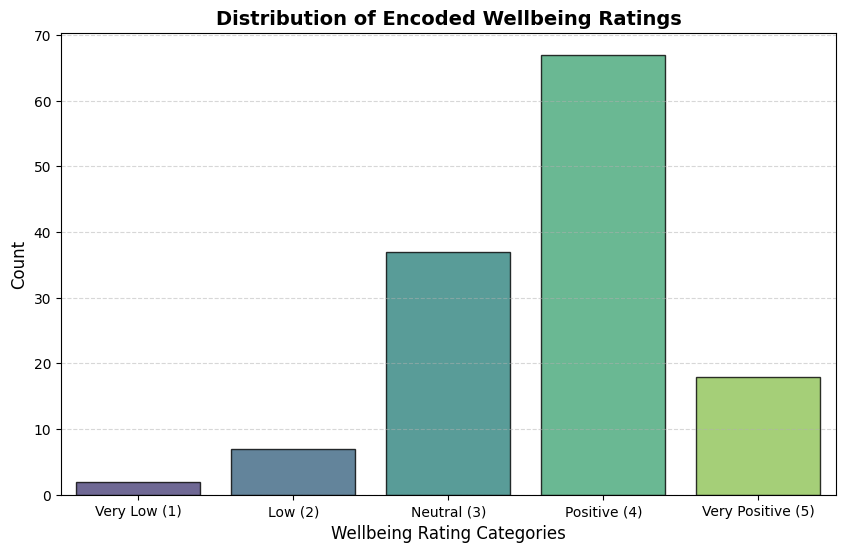

In [92]:
# @title
# Filter NaNs and plot the distribution of all 5 levels
wellbeing_counts = df['wellbeing_encoded'].dropna().value_counts().sort_index()

# Descriptive labels for the plot x-axis
labels = ['Very Low (1)', 'Low (2)', 'Neutral (3)', 'Positive (4)', 'Very Positive (5)']
# Ensure we align labels with the ratings present in our sorted index
plot_labels = [labels[int(i) - 1] for i in wellbeing_counts.index]

plt.figure(figsize=(10, 6))
sns.barplot(x=plot_labels, y=wellbeing_counts.values, palette='viridis', hue=plot_labels, legend=False, edgecolor='black', alpha=0.8)

plt.title('Distribution of Encoded Wellbeing Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Wellbeing Rating Categories', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

## **New Dataframe with encoded columns**

In [102]:
# @title
# Create a new DataFrame with only the encoded sound level and wellbeing data
df_encoded = df[['sound_level_encoded', 'wellbeing_encoded']].dropna()

print("Encoded DataFrame successfully created!")
print(f"Shape of encoded dataset: {df_encoded.shape}")
display(df_encoded.head())

for col in df_encoded:
  print(col)


Encoded DataFrame successfully created!
Shape of encoded dataset: (131, 2)


,sound_level_encoded,wellbeing_encoded
0,0.0,4.0
1,1.0,4.0
2,0.0,4.0
3,1.0,4.0
4,1.0,4.0


sound_level_encoded
wellbeing_encoded


## **K-Mean Plot of Well-Being in relation to Sound Level**

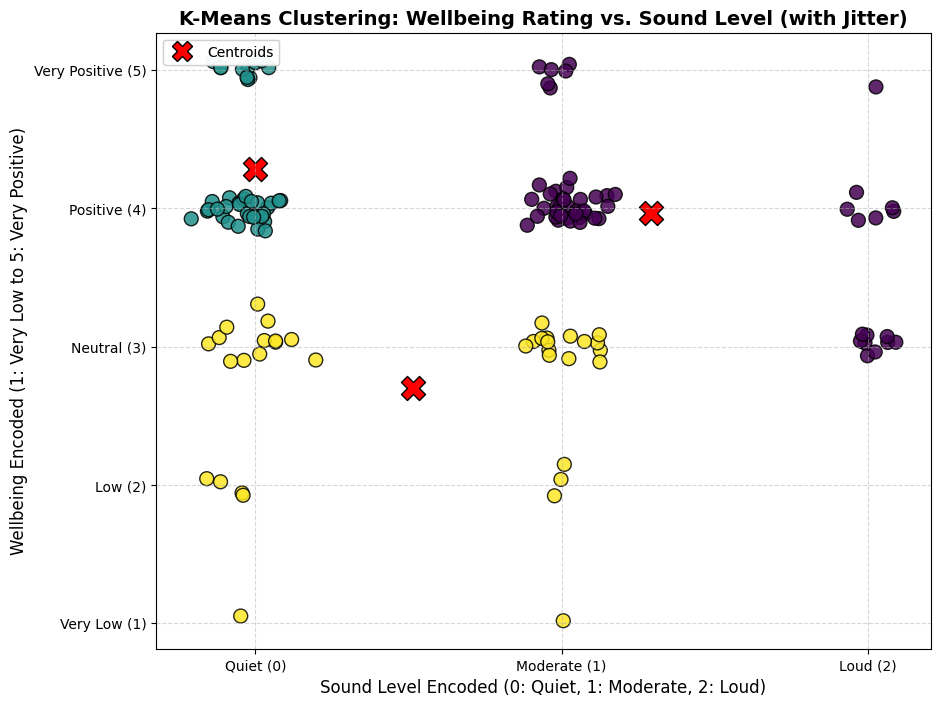

In [103]:
import numpy as np
from sklearn.cluster import KMeans

# Ensure we have our clean encoded dataframe
df_encoded = df[['sound_level_encoded', 'wellbeing_encoded']].dropna().copy()

# Fit K-Means on the 2D data (e.g., k=3 clusters)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_encoded['cluster'] = kmeans.fit_predict(df_encoded)

# Adding random jitter to visualize discrete values without overlapping
np.random.seed(42)
jitter_x = np.random.normal(0, 0.08, size=len(df_encoded))
jitter_y = np.random.normal(0, 0.08, size=len(df_encoded))

plt.figure(figsize=(10, 8))

# Scatter plot colored by K-Means cluster assignment
scatter = plt.scatter(
    df_encoded['sound_level_encoded'] + jitter_x,
    df_encoded['wellbeing_encoded'] + jitter_y,
    c=df_encoded['cluster'],
    cmap='viridis',
    s=100,
    alpha=0.85,
    edgecolors='black'
)

# Plot the centroids
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    marker='X',
    s=300,
    label='Centroids',
    edgecolors='black'
)

plt.title('K-Means Clustering: Wellbeing Rating vs. Sound Level (with Jitter)', fontsize=14, fontweight='bold')
plt.xlabel('Sound Level Encoded (0: Quiet, 1: Moderate, 2: Loud)', fontsize=12)
plt.ylabel('Wellbeing Encoded (1: Very Low to 5: Very Positive)', fontsize=12)
plt.xticks([0, 1, 2], ['Quiet (0)', 'Moderate (1)', 'Loud (2)'])
plt.yticks([1, 2, 3, 4, 5], ['Very Low (1)', 'Low (2)', 'Neutral (3)', 'Positive (4)', 'Very Positive (5)'])

# Legend for clusters and centroids
plt.legend(*scatter.legend_elements(), title="Clusters", loc="lower left")
plt.gca().add_artist(plt.legend([plt.Line2D([0], [0], marker='X', color='red', linestyle='', markersize=15, markeredgecolor='black')], ['Centroids'], loc='upper left'))

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## **Train the Machine**